# Part D: KNN


## 1. Environment Setup & Library Ingestion


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
from IPython.display import display

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Styling configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
print("Environment and machine learning libraries loaded successfully.")


Environment and machine learning libraries loaded successfully.


## 2. Preprocessed Data Ingestion & Partition Verification


In [9]:
# Ingest preprocessed splits
df_train = pd.read_csv('credit_train_preprocessed.csv')
df_test = pd.read_csv('credit_test_preprocessed.csv')

# Separate feature matrices and target vectors
X_train = df_train.drop(columns=['dpnm'])
y_train = df_train['dpnm']

X_test = df_test.drop(columns=['dpnm'])
y_test = df_test['dpnm']

print("=== DATASET DIMENSIONS & BALANCE SUMMARY ===")
print(f"Training Features Matrix (X_train): {X_train.shape[0]:,} rows x {X_train.shape[1]} features")
print(f"Training Target (y_train balance):  {y_train.value_counts().to_dict()} (50:50 SMOTE Balanced)")
print(f"Testing Features Matrix (X_test):   {X_test.shape[0]:,} rows x {X_test.shape[1]} features")
print(f"Testing Target (y_test balance):    {y_test.value_counts().to_dict()} (Authentic Unbalanced Test Set)")


=== DATASET DIMENSIONS & BALANCE SUMMARY ===
Training Features Matrix (X_train): 37,336 rows x 30 features
Training Target (y_train balance):  {0: 18668, 1: 18668} (50:50 SMOTE Balanced)
Testing Features Matrix (X_test):   5,993 rows x 30 features
Testing Target (y_test balance):    {0: 4667, 1: 1326} (Authentic Unbalanced Test Set)


## 3. Algorithm Principles & Mathematical Framework


## 4. Baseline KNN Model Training & Latency Profiling


In [10]:
# Instantiate baseline KNN model
knn_baseline = KNeighborsClassifier(
    n_neighbors=5,
    weights='uniform',
    metric='minkowski',
    p=2,
    n_jobs=-1
)

# Profile model training time
start_train = time.time()
knn_baseline.fit(X_train, y_train)
train_duration = time.time() - start_train

print(f"KNN Model Training Complete.")
print(f"Training Duration (Fit Time): {train_duration:.4f} seconds")
print(f"Algorithm Type: Non-parametric Lazy Learner (Training stores instance matrix in index structures)")


KNN Model Training Complete.
Training Duration (Fit Time): 0.0101 seconds
Algorithm Type: Non-parametric Lazy Learner (Training stores instance matrix in index structures)


## 5. Test Inference & Latency Evaluation


In [11]:
# Profile discrete class predictions
start_pred = time.time()
y_pred = knn_baseline.predict(X_test)
pred_duration = time.time() - start_pred

# Profile probability score estimation
start_prob = time.time()
y_prob = knn_baseline.predict_proba(X_test)[:, 1]
prob_duration = time.time() - start_prob

total_inference_time = pred_duration + prob_duration
per_sample_latency_ms = (pred_duration / len(X_test)) * 1000

print(f"=== INFERENCE LATENCY BENCHMARK ===")
print(f"Total Test Set Records Evaluated: {len(X_test):,} queries")
print(f"Total Class Prediction Time:      {pred_duration:.4f} seconds")
print(f"Total Probability Scoring Time:   {prob_duration:.4f} seconds")
print(f"Average Latency Per Query:        {per_sample_latency_ms:.3f} ms/query")


=== INFERENCE LATENCY BENCHMARK ===
Total Test Set Records Evaluated: 5,993 queries
Total Class Prediction Time:      0.3473 seconds
Total Probability Scoring Time:   0.2628 seconds
Average Latency Per Query:        0.058 ms/query


## 6. Confusion Matrix & Detailed Classification Report


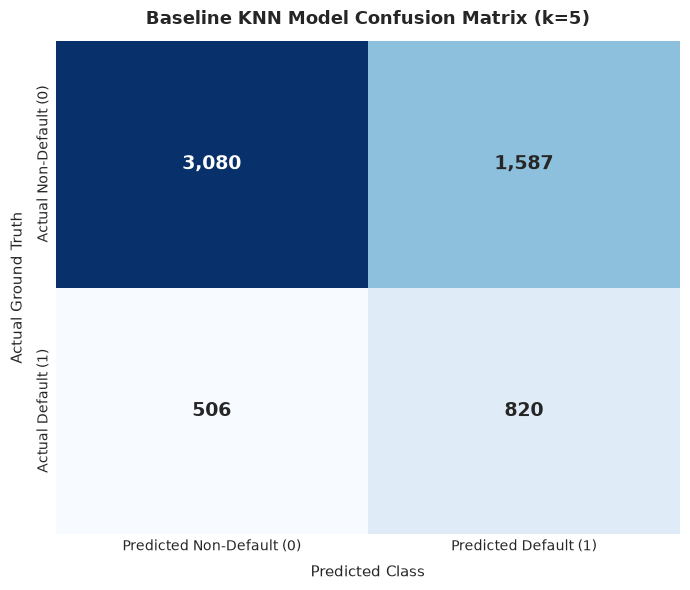

=== CONFUSION MATRIX CELL VALUES ===
True Negatives  (TN - Correct Non-Default): 3,080 accounts
False Positives (FP - False Alarm):         1,587 accounts
False Negatives (FN - Costly Missed Risk):  506 accounts
True Positives  (TP - Detected Default):    820 accounts

=== CLASSIFICATION REPORT ===
                 precision    recall  f1-score   support

Non-Default (0)     0.8589    0.6600    0.7464      4667
    Default (1)     0.3407    0.6184    0.4393      1326

       accuracy                         0.6508      5993
      macro avg     0.5998    0.6392    0.5929      5993
   weighted avg     0.7442    0.6508    0.6785      5993



In [12]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

# Plot styled Confusion Matrix heatmap
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm, annot=True, fmt=',d', cmap='Blues', cbar=False,
    xticklabels=['Predicted Non-Default (0)', 'Predicted Default (1)'],
    yticklabels=['Actual Non-Default (0)', 'Actual Default (1)'],
    annot_kws={'size': 14, 'weight': 'bold'}
)
plt.title('Baseline KNN Model Confusion Matrix (k=5)', fontsize=13, weight='bold', pad=12)
plt.xlabel('Predicted Class', fontsize=11, labelpad=8)
plt.ylabel('Actual Ground Truth', fontsize=11, labelpad=8)
plt.tight_layout()
plt.show()

print("=== CONFUSION MATRIX CELL VALUES ===")
print(f"True Negatives  (TN - Correct Non-Default): {tn:,} accounts")
print(f"False Positives (FP - False Alarm):         {fp:,} accounts")
print(f"False Negatives (FN - Costly Missed Risk):  {fn:,} accounts")
print(f"True Positives  (TP - Detected Default):    {tp:,} accounts")
print("\n=== CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred, target_names=['Non-Default (0)', 'Default (1)'], digits=4))


## 7. Core Performance Metrics & ROC-AUC Analysis


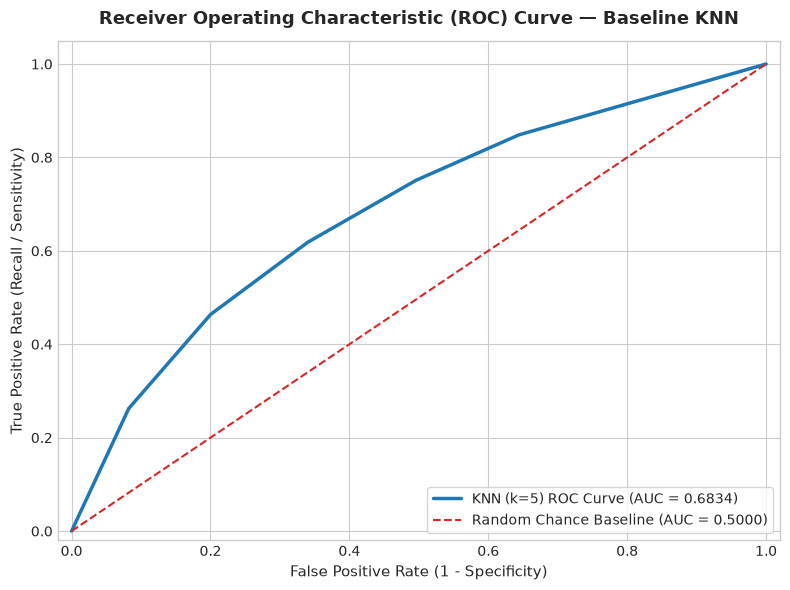

,Metric,Score,Banking Significance
0,Accuracy,0.6508,Proportion of total correct credit predictions...
1,Precision (Default),0.3407,Fraction of flagged accounts that truly defaul...
2,Recall / Sensitivity (Default),0.6184,Fraction of actual defaulters caught (critical...
3,F1-Score (Default),0.4393,Harmonic mean balancing precision and sensitiv...
4,ROC-AUC Score,0.6834,Overall ranking capability across all potentia...


In [13]:
# Calculate performance metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

# Compute ROC Curve coordinates
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Plot styled ROC Curve
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'KNN (k=5) ROC Curve (AUC = {roc_auc:.4f})')
ax.plot([0, 1], [0, 1], color='#d62728', lw=1.5, linestyle='--', label='Random Chance Baseline (AUC = 0.5000)')

ax.set_xlim([-0.02, 1.02])
ax.set_ylim([-0.02, 1.05])
ax.set_xlabel('False Positive Rate (1 - Specificity)', fontsize=11)
ax.set_ylabel('True Positive Rate (Recall / Sensitivity)', fontsize=11)
ax.set_title('Receiver Operating Characteristic (ROC) Curve, Baseline KNN', fontsize=13, weight='bold', pad=12)
ax.legend(loc='lower right', frameon=True, fontsize=10)
plt.tight_layout()
plt.show()

# Display summary metrics table
metrics_df = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Default)', 'Recall / Sensitivity (Default)', 'F1-Score (Default)', 'ROC-AUC Score'],
    'Score': [f"{acc:.4f}", f"{prec:.4f}", f"{rec:.4f}", f"{f1:.4f}", f"{roc_auc:.4f}"],
    'Banking Significance': [
        'Proportion of total correct credit predictions (baseline naive = 0.7788)',
        'Fraction of flagged accounts that truly defaulted (lower precision = more false alerts)',
        'Fraction of actual defaulters caught (critical for minimizing uncollected debt losses)',
        'Harmonic mean balancing precision and sensitivity on credit default',
        'Overall ranking capability across all potential decision thresholds'
    ]
})
display(metrics_df)


## 8. Critical Model Evaluation & Technical Discussion


## 9. Final Summary Table & Phase Completion


In [14]:
summary_table = pd.DataFrame({
    'Component': [
        'Model Algorithm', 'Hyperparameter Setting', 'Training Observations',
        'Testing Observations', 'Fit Time (s)', 'Inference Time (s)',
        'Accuracy', 'Precision (Default)', 'Recall (Default)', 'F1-Score', 'ROC-AUC'
    ],
    'Value': [
        'K-Nearest Neighbors (KNN)', 'k=5, metric=minkowski (p=2), weights=uniform', f"{X_train.shape[0]:,}",
        f"{X_test.shape[0]:,}", f"{train_duration:.4f}", f"{pred_duration:.4f}",
        f"{acc:.4f}", f"{prec:.4f}", f"{rec:.4f}", f"{f1:.4f}", f"{roc_auc:.4f}"
    ]
})

print("=== PART D BASELINE KNN MODEL SUMMARY ===")
display(summary_table)
print("\nPart D baseline KNN model implementation complete. Ready for hyperparameter optimization in Part E.")


=== PART D BASELINE KNN MODEL SUMMARY ===


,Component,Value
0,Model Algorithm,K-Nearest Neighbors (KNN)
1,Hyperparameter Setting,"k=5, metric=minkowski (p=2), weights=uniform"
2,Training Observations,"37,336"
3,Testing Observations,"5,993"
4,Fit Time (s),0.0101
5,Inference Time (s),0.3473
6,Accuracy,0.6508
7,Precision (Default),0.3407
8,Recall (Default),0.6184
9,F1-Score,0.4393



Part D baseline KNN model implementation complete. Ready for hyperparameter optimization in Part E.
